<a href="https://colab.research.google.com/github/Nithya-2-2/MLImaging/blob/main/Week7_Cat_Dolphin_MLP_NN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



---



# **Image Classification of Cats and Dolphins Using Multi-Layer Perceptron (MLP) Neural Networks**



---



## Aim

To classify Cat and Dolphin images using a Multi-Layer Perceptron (MLP) Neural Network and evaluate the impact of different architectures, solvers, learning rate schedules, and data normalization techniques on classification performance.

## Objectives



1.   Load and preprocess image data.
2.   Convert images into feature vectors.
4. Train an MLP neural network using the extracted features.
5. Experiment with different network architectures.
6. Investigate model complexity by comparing networks with different numbers of hidden layers and different numbers of units per layer.
7. Compare training and validation performance to identify underfitting and overfitting.
8. Plot training and testing/validation error and examine the MLP loss curve.
9. Compare model performance, training time and network complexity.
10. Identify and justify the best-performing solution for Cat and Dolphin image classification.
11. Evaluate the final selected model using a confusion matrix and classification report.
12. Investigate the effect of feature scaling/normalisation on model performance.




---



1. Import Libraries

In [55]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import time
import random


import glob
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler
from sklearn.neural_network import MLPClassifier
from skimage.feature import local_binary_pattern, hog
from skimage.feature import hog as skimage_hog

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Libraries imported successfully")


Libraries imported successfully


2. Load Dataset

In [56]:
from google.colab import drive
drive.mount('/content/drive')

SIZE = 128

images = []
labels = []

def load_rgb(path):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (SIZE, SIZE))
    return img

for folder in sorted(glob.glob(
    "/content/drive/MyDrive/MLImaging/ML_IPData/*"
)):
    label = os.path.basename(folder).title()

    for path in glob.glob(os.path.join(folder, "*.jpg")):
        img = load_rgb(path)
        images.append(img)
        labels.append(label)

images = np.array(images)
labels = np.array(labels)

print("Total images:", len(images))
print("Image shape:", images.shape)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Total images: 1684
Image shape: (1684, 128, 128, 3)


3. Display sample images and pixel values

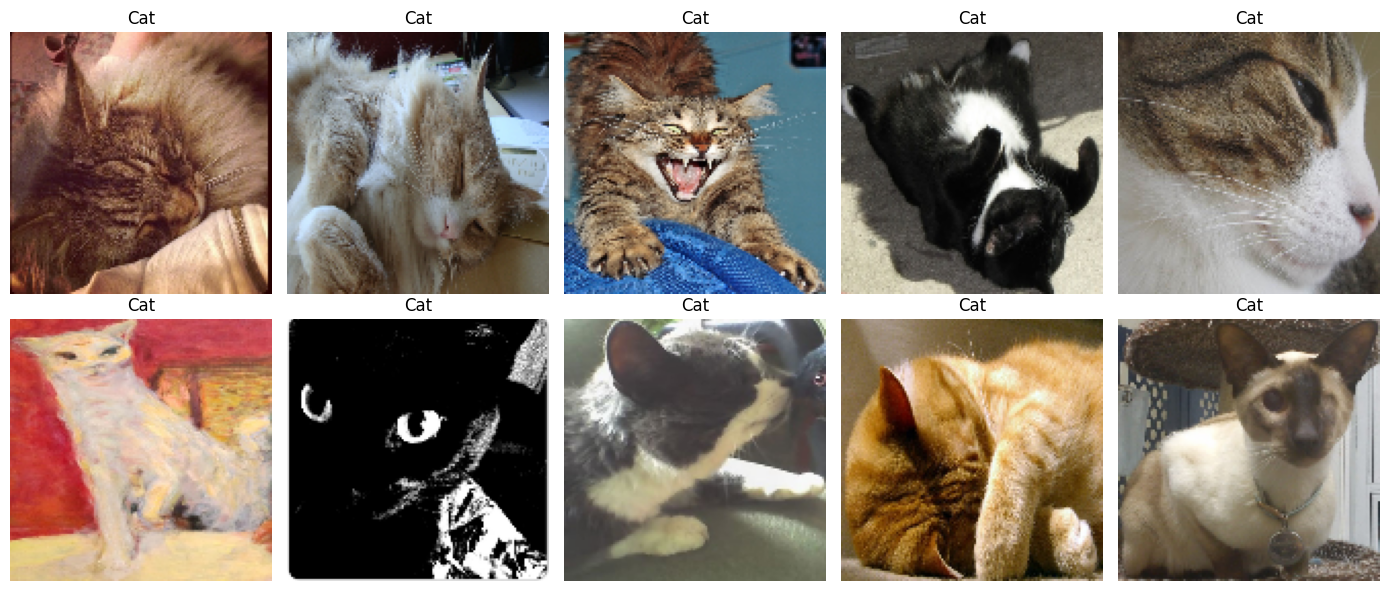

Sample RGB pixel values:
[[[ 36   1   1]
  [107  52  44]
  [139  72  59]
  [143  79  61]
  [133  68  52]]

 [[ 50   8   6]
  [136  76  62]
  [143  77  61]
  [140  74  60]
  [135  68  59]]

 [[ 83  36  32]
  [135  74  60]
  [144  78  62]
  [147  85  71]
  [135  75  65]]

 [[ 87  38  34]
  [136  76  65]
  [144  82  69]
  [141  79  66]
  [127  69  57]]

 [[ 91  40  36]
  [145  84  71]
  [145  82  72]
  [148  85  76]
  [145  82  75]]]


In [57]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i])
    ax.set_title(labels[i])
    ax.axis('off')

plt.tight_layout()
plt.show()

# Display pixel values from one sample image
print("Sample RGB pixel values:")
print(images[0][:5, :5, :])

4. RGB histogram visualisation

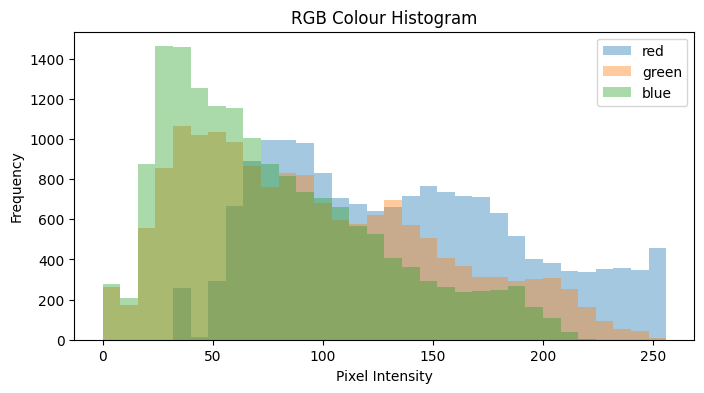

In [58]:
sample = images[0]

plt.figure(figsize=(8, 4))

for channel, colour in enumerate(['red', 'green', 'blue']):
    plt.hist(
        sample[:, :, channel].ravel(),
        bins=32,
        range=(0, 256),
        alpha=0.4,
        label=colour
    )

plt.title("RGB Colour Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.legend()
plt.show()

5. Extract Features - RGB and HOG

In [59]:
# RGB features
def rgb_feature(img):
    features = []

    for channel in range(3):
        features.append(np.mean(img[:, :, channel]))
        features.append(np.std(img[:, :, channel]))

    return np.array(features)


# HOG features
def hog_feature(img):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    return hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        feature_vector=True
    )


rgb_features = np.array([rgb_feature(img) for img in images])
hog_features = np.array([hog_feature(img) for img in images])

print("RGB shape:", rgb_features.shape)
print("HOG shape:", hog_features.shape)

RGB shape: (1684, 6)
HOG shape: (1684, 8100)


5.1 Visualise HOG Features

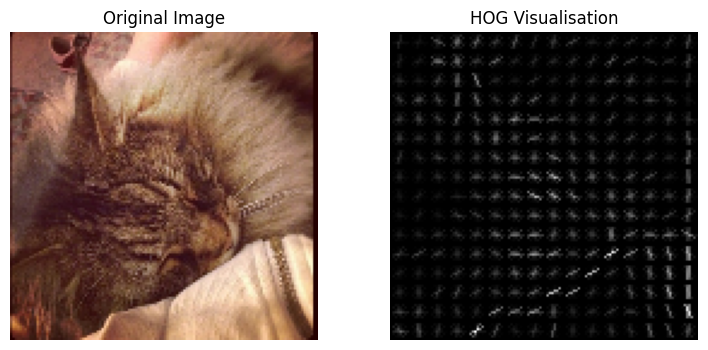

In [60]:
gray = cv2.cvtColor(images[0], cv2.COLOR_RGB2GRAY)

hog_image, hog_visual = hog(
    gray,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True
)

plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)
plt.imshow(images[0])
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(hog_visual, cmap='gray')
plt.title("HOG Visualisation")
plt.axis('off')

plt.show()

 6. Prepare Training, Validation and testing data

In [61]:
le = LabelEncoder()
y = le.fit_transform(labels)

features = {
    "RGB": rgb_features,
    "HOG": hog_features
}

splits = {}

for name, X in features.items():

    X_trainval, X_test, y_trainval, y_test = train_test_split(
        X, y,
        test_size=0.15,
        random_state=SEED,
        stratify=y
    )

    X_train, X_val, y_train, y_val = train_test_split(
        X_trainval, y_trainval,
        test_size=0.1765,
        random_state=SEED,
        stratify=y_trainval
    )

    splits[name] = (
        X_train, X_val, X_test,
        y_train, y_val, y_test
    )

print("Training, validation and testing data prepared.")

Training, validation and testing data prepared.


7. Compare different network architectures

In [62]:
architectures = {
    "M1": (32,),
    "M2": (64,),
    "M3": (100,),
    "M4": (64, 32),
    "M5": (100, 50),
    "M6": (128, 64, 32)
}

architecture_results = []
architecture_models = {}

for feature_name, data in splits.items():

    X_train, X_val, X_test, y_train, y_val, y_test = data

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)

    for name, layers in architectures.items():

        model = MLPClassifier(
            hidden_layer_sizes=layers,
            activation='relu',
            solver='adam',
            max_iter=200,
            early_stopping=True,
            random_state=SEED
        )

        start = time.time()
        model.fit(X_train_scaled, y_train)
        training_time = time.time() - start

        train_accuracy = model.score(X_train_scaled, y_train)
        val_accuracy = model.score(X_val_scaled, y_val)

        architecture_models[(feature_name, name)] = model

        architecture_results.append({
            "Feature": feature_name,
            "Model": name,
            "Layers and Units": str(layers),
            "Parameters": sum(
                (a + 1) * b
                for a, b in zip(
                    [X_train.shape[1]] + list(layers),
                    list(layers) + [len(le.classes_)]
                )
            ),
            "Training Accuracy": train_accuracy * 100,
            "Validation Accuracy": val_accuracy * 100,
            "Training Time": training_time
        })

architecture_results = pd.DataFrame(architecture_results)

display(
    architecture_results.sort_values(
        "Validation Accuracy", ascending=False
    ).round(2)
)

,Feature,Model,Layers and Units,Parameters,Training Accuracy,Validation Accuracy,Training Time
2,RGB,M3,"(100,)",902,87.78,85.77,0.16
0,RGB,M1,"(32,)",290,88.62,84.98,0.24
5,RGB,M6,"(128, 64, 32)",11298,89.73,84.98,0.31
4,RGB,M5,"(100, 50)",5852,88.96,84.98,0.21
3,RGB,M4,"(64, 32)",2594,89.13,84.58,0.18
1,RGB,M2,"(64,)",578,85.65,83.79,0.13
10,HOG,M5,"(100, 50)",815252,96.10,79.84,3.85
9,HOG,M4,"(64, 32)",520610,97.37,79.45,3.52
11,HOG,M6,"(128, 64, 32)",1047330,97.79,78.66,10.24
6,HOG,M1,"(32,)",259298,92.95,74.70,1.55


8. Compare Model Complexity and performance

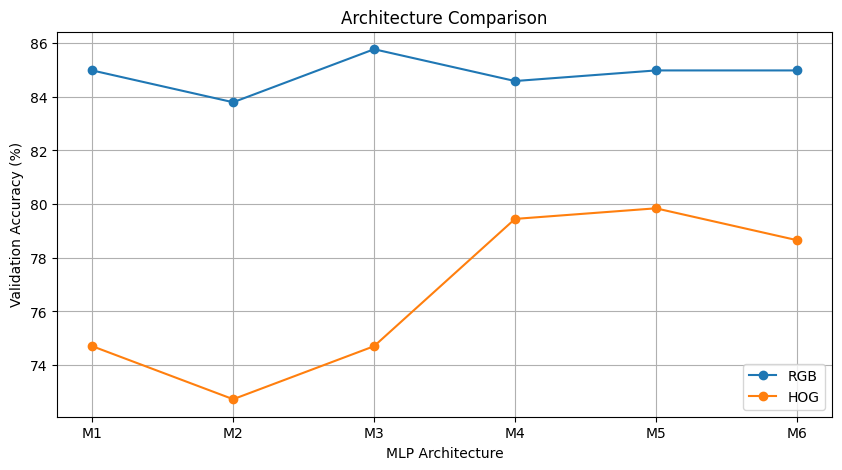

In [63]:
plt.figure(figsize=(10, 5))

for feature in ['RGB', 'HOG']:

    data = architecture_results[
        architecture_results['Feature'] == feature
    ]

    plt.plot(
        data['Model'],
        data['Validation Accuracy'],
        marker='o',
        label=feature
    )

plt.title("Architecture Comparison")
plt.xlabel("MLP Architecture")
plt.ylabel("Validation Accuracy (%)")
plt.legend()
plt.grid()
plt.show()

9. Training time comparison

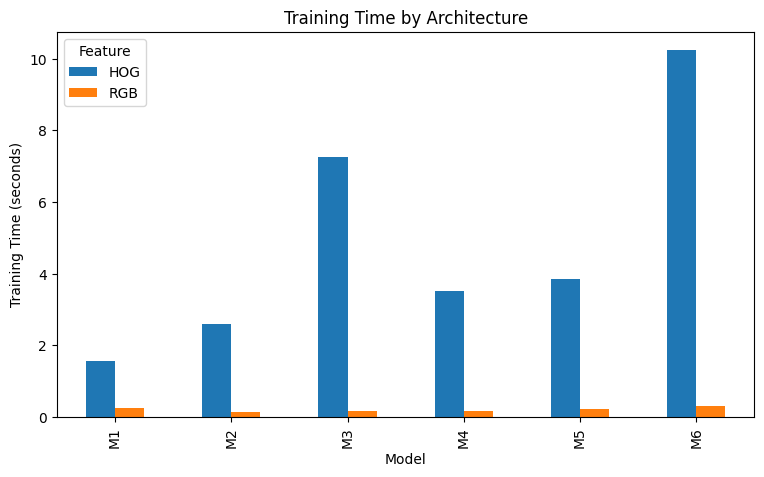

In [64]:
architecture_results.pivot(
    index='Model',
    columns='Feature',
    values='Training Time'
).plot(kind='bar', figsize=(9, 5))

plt.title("Training Time by Architecture")
plt.ylabel("Training Time (seconds)")
plt.show()

10. Effect of Normalisation


> comparing No scaling, StandardScaler, MinMaxScaler



In [65]:
best_row = architecture_results.loc[
    architecture_results['Validation Accuracy'].idxmax()
]

best_feature = best_row['Feature']
best_architecture = architectures[best_row['Model']]

print("Best feature:", best_feature)
print("Best architecture:", best_architecture)

X_train, X_val, X_test, y_train, y_val, y_test = splits[best_feature]

scaling_methods = {
    "No Scaling": None,
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler()
}

normalisation_results = []

for name, scaler in scaling_methods.items():

    if scaler is None:
        Xtr, Xv = X_train, X_val
    else:
        Xtr = scaler.fit_transform(X_train)
        Xv = scaler.transform(X_val)

    model = MLPClassifier(
        hidden_layer_sizes=best_architecture,
        max_iter=200,
        early_stopping=True,
        random_state=SEED
    )

    start = time.time()
    model.fit(Xtr, y_train)
    elapsed = time.time() - start

    normalisation_results.append({
        "Scaling": name,
        "Training Accuracy": model.score(Xtr, y_train) * 100,
        "Validation Accuracy": model.score(Xv, y_val) * 100,
        "Training Time": elapsed
    })

normalisation_results = pd.DataFrame(normalisation_results)

display(normalisation_results.round(2))

Best feature: RGB
Best architecture: (100,)


,Scaling,Training Accuracy,Validation Accuracy,Training Time
0,No Scaling,88.12,85.77,0.11
1,StandardScaler,87.78,85.77,0.20
2,MinMaxScaler,73.68,67.98,0.09


10.1 Normalisation graph

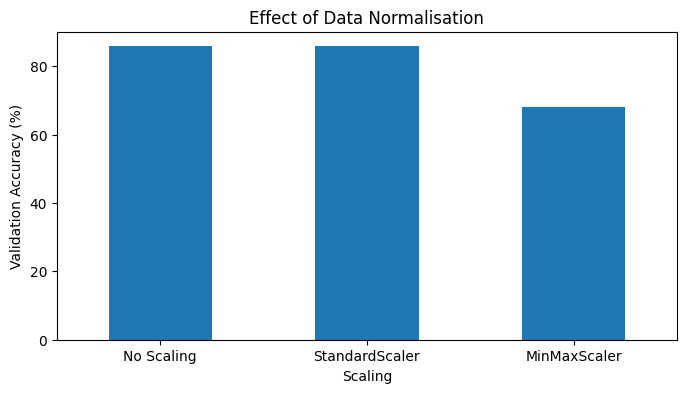

In [66]:
normalisation_results.plot(
    x='Scaling',
    y='Validation Accuracy',
    kind='bar',
    legend=False,
    figsize=(8, 4)
)

plt.title("Effect of Data Normalisation")
plt.ylabel("Validation Accuracy (%)")
plt.xticks(rotation=0)
plt.show()

10.2 Compare solvers and learning rate schedules

In [67]:
solver_configs = [
    ("Adam", "adam", "constant"),
    ("LBFGS", "lbfgs", "constant"),
    ("SGD Constant", "sgd", "constant"),
    ("SGD Invscaling", "sgd", "invscaling"),
    ("SGD Adaptive", "sgd", "adaptive")
]

# Select the best scaling method using validation accuracy
best_scaling = normalisation_results.loc[
    normalisation_results['Validation Accuracy'].idxmax(),
    'Scaling'
]

best_scaler = (
    None if best_scaling == "No Scaling"
    else StandardScaler() if best_scaling == "StandardScaler"
    else MinMaxScaler()
)

if best_scaler is None:
    Xtr, Xv = X_train, X_val
else:
    Xtr = best_scaler.fit_transform(X_train)
    Xv = best_scaler.transform(X_val)

solver_results = []
solver_models = {}

for name, solver, learning_rate in solver_configs:

    model = MLPClassifier(
        hidden_layer_sizes=best_architecture,
        solver=solver,
        learning_rate=learning_rate,
        learning_rate_init=0.001,
        max_iter=200,
        early_stopping=(solver != "lbfgs"),
        random_state=SEED
    )

    start = time.time()
    model.fit(Xtr, y_train)
    elapsed = time.time() - start

    solver_models[name] = model

    solver_results.append({
        "Solver": name,
        "Training Accuracy": model.score(Xtr, y_train) * 100,
        "Validation Accuracy": model.score(Xv, y_val) * 100,
        "Training Time": elapsed
    })

solver_results = pd.DataFrame(solver_results)

display(solver_results.round(2))

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


,Solver,Training Accuracy,Validation Accuracy,Training Time
0,Adam,88.12,85.77,0.11
1,LBFGS,90.66,85.77,2.34
2,SGD Constant,88.54,85.77,0.13
3,SGD Invscaling,87.78,86.56,0.11
4,SGD Adaptive,90.66,84.98,0.32


10.3 Solver performance graphs

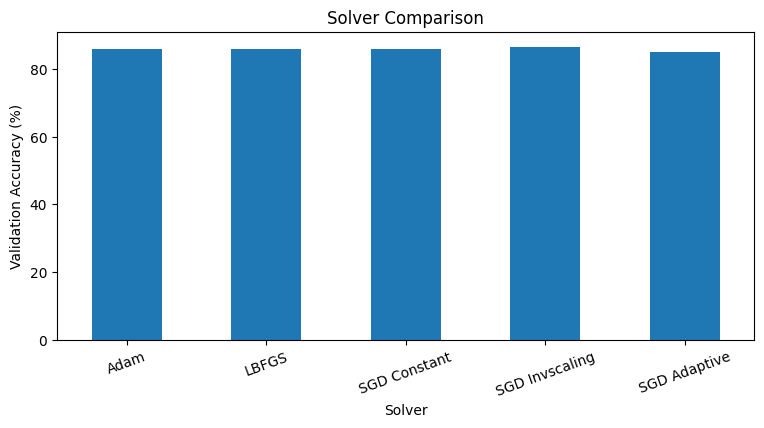

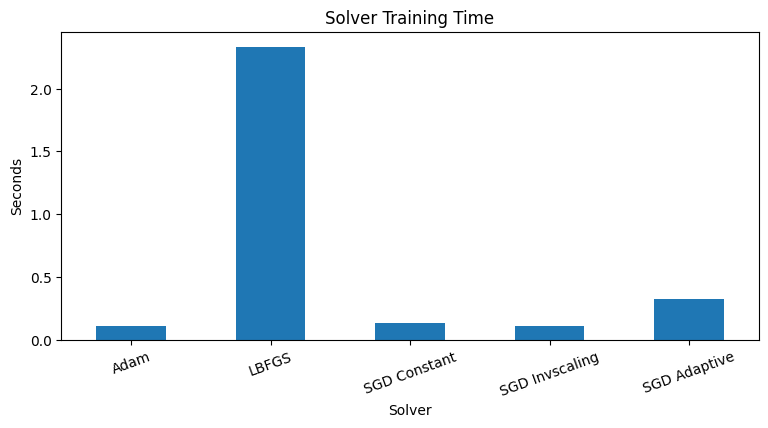

In [68]:
solver_results.plot(
    x='Solver',
    y='Validation Accuracy',
    kind='bar',
    legend=False,
    figsize=(9, 4)
)

plt.title("Solver Comparison")
plt.ylabel("Validation Accuracy (%)")
plt.xticks(rotation=20)
plt.show()

solver_results.plot(
    x='Solver',
    y='Training Time',
    kind='bar',
    legend=False,
    figsize=(9, 4)
)

plt.title("Solver Training Time")
plt.ylabel("Seconds")
plt.xticks(rotation=20)
plt.show()

10.4 Training loss and Validation score graphs

Best solver: SGD Invscaling


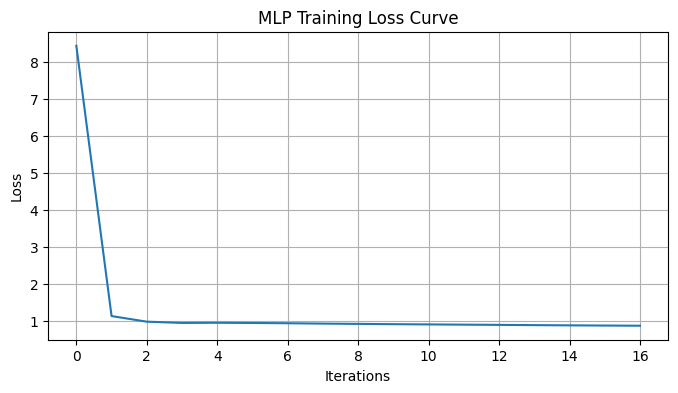

In [69]:
best_solver_name = solver_results.loc[
    solver_results['Validation Accuracy'].idxmax(),
    'Solver'
]

best_solver_model = solver_models[best_solver_name]

print("Best solver:", best_solver_name)

# Training loss
plt.figure(figsize=(8, 4))
plt.plot(best_solver_model.loss_curve_)
plt.title("MLP Training Loss Curve")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.grid()
plt.show()

10.5 Validation scores

SGD Invscaling
MLPClassifier(early_stopping=True, learning_rate='invscaling', random_state=42,
              solver='sgd')


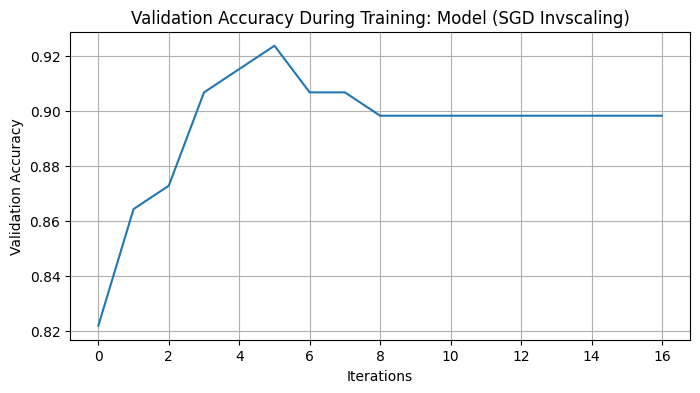

In [70]:
if hasattr(best_solver_model, 'validation_scores_'):

    #print(solver_models)
    #print(solver_results)
    best_solver_name = solver_results.loc[
    solver_results['Validation Accuracy'].idxmax(),
    'Solver']
    print(best_solver_name)

    plt.figure(figsize=(8, 4))
    print(best_solver_model)

    plt.plot(best_solver_model.validation_scores_)
    #best_solver_name = solver_results.loc[
    #solver_results['Validation Accuracy'].idxmax(),
    #'Solver'
    #]

    plt.title(f"Validation Accuracy During Training: Model ({best_solver_name})")
    plt.xlabel("Iterations")
    plt.ylabel("Validation Accuracy")
    plt.grid()
    plt.show()

else:
    print("Validation scores are not available for LBFGS.")

11. Underfitting and Overfitting

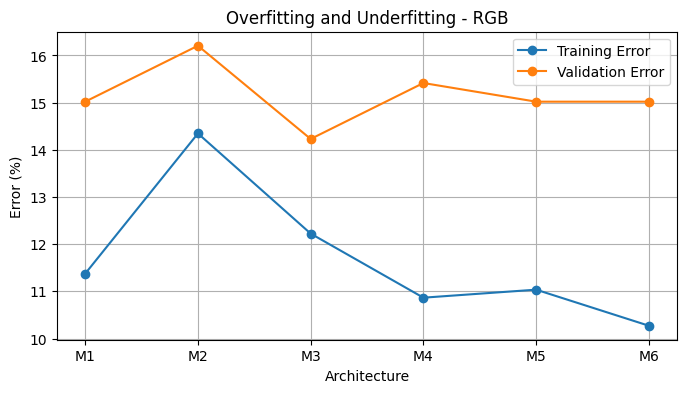

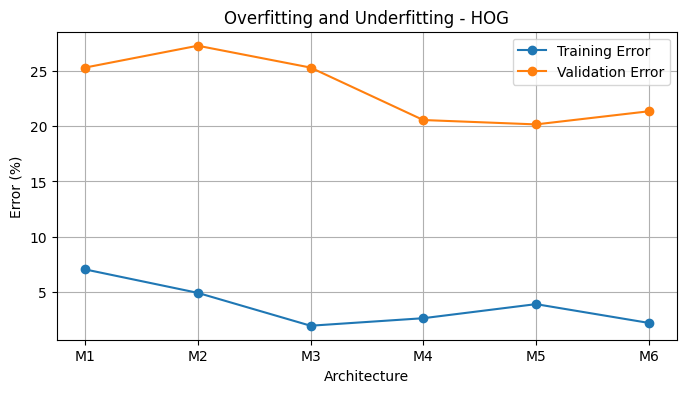

In [71]:
architecture_results['Training Error'] = (
    100 - architecture_results['Training Accuracy']
)

architecture_results['Validation Error'] = (
    100 - architecture_results['Validation Accuracy']
)

for feature in ['RGB', 'HOG']:

    data = architecture_results[
        architecture_results['Feature'] == feature
    ]

    plt.figure(figsize=(8, 4))

    plt.plot(data['Model'], data['Training Error'],
             marker='o', label='Training Error')

    plt.plot(data['Model'], data['Validation Error'],
             marker='o', label='Validation Error')

    plt.title(f"Overfitting and Underfitting - {feature}")
    plt.xlabel("Architecture")
    plt.ylabel("Error (%)")
    plt.legend()
    plt.grid()
    plt.show()

12. Select and train the best model

In [72]:
# Get the selected solver configuration
solver_info = next(
    config for config in solver_configs
    if config[0] == best_solver_name
)

_, best_solver, best_learning_rate = solver_info

# Combine training and validation data
X_trainval = np.vstack((X_train, X_val))
y_trainval = np.concatenate((y_train, y_val))

# Fit the selected scaler on all training data
if best_scaling == "StandardScaler":
    final_scaler = StandardScaler()
elif best_scaling == "MinMaxScaler":
    final_scaler = MinMaxScaler()
else:
    final_scaler = None

if final_scaler is not None:
    X_trainval_final = final_scaler.fit_transform(X_trainval)
    X_test_final = final_scaler.transform(X_test)
else:
    X_trainval_final = X_trainval
    X_test_final = X_test

# Train final MLP model
final_model = MLPClassifier(
    hidden_layer_sizes=best_architecture,
    activation='relu',
    solver=best_solver,
    learning_rate=best_learning_rate,
    learning_rate_init=0.001,
    #max_iter=300,
    random_state=SEED
)

start = time.time()

final_model.fit(X_trainval_final, y_trainval)

final_training_time = time.time() - start

print("Best feature:", best_feature)
print("Best architecture:", best_architecture)
print("Best scaling:", best_scaling)
print("Best solver:", best_solver_name)
print("Training time:", round(final_training_time, 2), "seconds")

Best feature: RGB
Best architecture: (100,)
Best scaling: No Scaling
Best solver: SGD Invscaling
Training time: 0.83 seconds


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


13. Final training loss curve

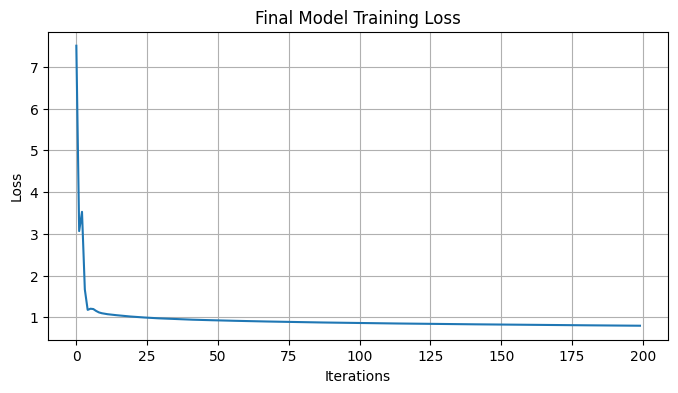

In [73]:
plt.figure(figsize=(8, 4))

plt.plot(final_model.loss_curve_)

plt.title("Final Model Training Loss")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.grid()
plt.show()

14. Final training and testing error graphs

Training Accuracy: 88.33 %
Testing Accuracy: 87.35 %
Training Error: 11.67 %
Testing Error: 12.648 %


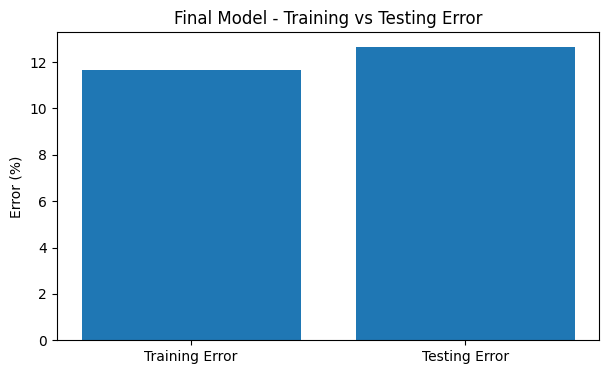

In [74]:
train_accuracy = final_model.score(
    X_trainval_final, y_trainval
)

test_accuracy = final_model.score(
    X_test_final, y_test
)

train_error = (1 - train_accuracy) * 100
test_error = (1 - test_accuracy) * 100

print("Training Accuracy:", round(train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")
print("Training Error:", round(train_error, 3), "%")
print("Testing Error:", round(test_error, 3), "%")
plt.figure(figsize=(7, 4))

plt.bar(
    ['Training Error', 'Testing Error'],
    [train_error, test_error]
)

plt.title("Final Model - Training vs Testing Error")
plt.ylabel("Error (%)")
plt.show()

15. Final evaluation - Confusion Matrix and Classification report

Classification Report
              precision    recall  f1-score   support

         Cat       0.86      0.91      0.88       131
     Dolphin       0.89      0.84      0.86       122

    accuracy                           0.87       253
   macro avg       0.88      0.87      0.87       253
weighted avg       0.87      0.87      0.87       253



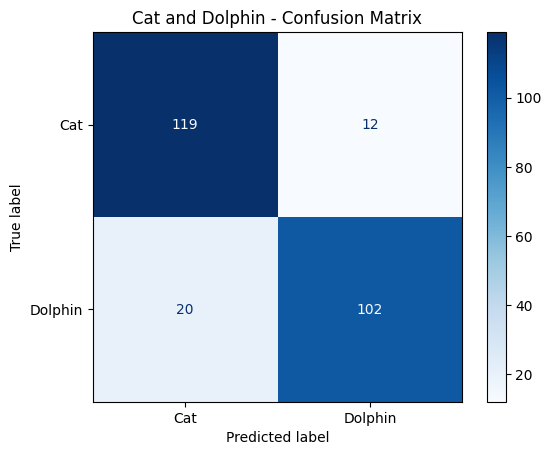

In [75]:
y_pred = final_model.predict(X_test_final)

print("Classification Report")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=le.classes_
    )
)

cm = confusion_matrix(y_test, y_pred)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le.classes_
)

display_matrix.plot(cmap='Blues')

plt.title("Cat and Dolphin - Confusion Matrix")
plt.show()

16. Final results and best solution

In [76]:
print("BEST MLP SOLUTION")
print("---------------------------")

print("Feature:", best_feature)
print("Architecture:", best_architecture)
print("Number of hidden layers:", len(best_architecture))
print("Units per layer:", best_architecture)
print("Normalisation:", best_scaling)
print("Solver:", best_solver_name)

print("\nFINAL PERFORMANCE")

print("Training Accuracy:", round(train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")
print("Training Error:", round(train_error, 3), "%")
print("Testing Error:", round(test_error, 3), "%")
print("Difference in Error (test-train):",test_error - train_error,"%")
print("Precision:", round(
    precision_score(y_test, y_pred, average='weighted'), 3
))

print("Recall:", round(
    recall_score(y_test, y_pred, average='weighted'), 3
))

print("F1 Score:", round(
    f1_score(y_test, y_pred, average='weighted'), 3
))

BEST MLP SOLUTION
---------------------------
Feature: RGB
Architecture: (100,)
Number of hidden layers: 1
Units per layer: (100,)
Normalisation: No Scaling
Solver: SGD Invscaling

FINAL PERFORMANCE
Training Accuracy: 88.33 %
Testing Accuracy: 87.35 %
Training Error: 11.67 %
Testing Error: 12.648 %
Difference in Error (test-train): 0.9780606171090227 %
Precision: 0.875
Recall: 0.874
F1 Score: 0.873


# Conclusion

The MLP neutral network successfully classified Cat and Dolphin images using RGB and HOG Feature extraction. Among the six architectures tested, RGB with M3 (100 hidden units, 902 parameters) achieved the highest validation accuracy of 85.771% with a training accuracy of 87.776%. (Ref [7](https://colab.research.google.com/drive/1APUgP37AKFmcj8qJfc-iuPo4grVKUp17#scrollTo=m1PQVwVwQUw9&line=2&uniqifier=1))

RGB features performed better than HOG features. HOG models showed signs of overfitting, with training accuracy reaching 98.048% while validation accuracy dropped to 74.704%. The RGB models demonstrated better generalisation, with smaller differences between training and validation errors. (Ref [7](https://colab.research.google.com/drive/1APUgP37AKFmcj8qJfc-iuPo4grVKUp17#scrollTo=m1PQVwVwQUw9&line=2&uniqifier=1))

For Normalisation, No Scaling and StandardScaler both achieved 85.771% validation accuracy, while MinMaxScaler achieved 67.984%. Among the solvers, SGD Invscaling achieved the highest validation accuracy of 85.561%, with a training time of 0.103 seconds. (Ref [10](https://colab.research.google.com/drive/1APUgP37AKFmcj8qJfc-iuPo4grVKUp17#scrollTo=J_lWCdQjRCab&line=2&uniqifier=1))

The final selected model used RGB features, 100 hidden units, No Scaling and SGD Invscaling. It achieved 88.33% training accuracy and 87.35% and F1-Score of 0.8732. The training and testing errors were 11.67% and 12.6%, respectively. The small difference of 0.97% between training and testing errors indicates good generalisation, with no significant evidence of overfitting or underfitting in the final model. (Ref [14](https://colab.research.google.com/drive/1APUgP37AKFmcj8qJfc-iuPo4grVKUp17#scrollTo=gXwhrqciaev3&line=1&uniqifier=1))

